# ❤️ Classificação de Doença Cardíaca com XGBoost Classifier

## 🩺 Sobre o Dataset

Este projeto utiliza o **Cleveland Heart Disease Dataset**, com informações clínicas como idade, colesterol, pressão arterial e exames para prever a presença de doença cardíaca.

- **Fonte:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/45/heart+disease)
- **Variável-alvo (`target`):** `0` = Sem Doença Cardíaca | `1` = Com Doença Cardíaca (graus 1 a 4 agrupados)
- **Observações totais:** 303
- **Após o tratamento dos nulos:** **303 registros mantidos** (valores ausentes de `ca` e `thal` preenchidos com a mediana; 297 seria o total caso fossem excluídas as linhas incompletas).

---

## 🚀 Pipeline do Projeto

| Etapa | Descrição |
|---|---|
| 📥 1. Carregamento | `pandas.read_csv` tratando `?` como nulo |
| 🧹 2. Tratamento de Nulos | Preenchimento de `ca` e `thal` com a **mediana** |
| 📊 3. Análise Exploratória | `info()`, `isnull()`, `describe()` e `head()` |
| ✂️ 4. Split | Treino/teste **80/20**, estratificado por classe |
| 🔍 5. Grid Search | Otimização de hiperparâmetros com **5 folds** |
| 🤖 6. Treinamento | **`XGBClassifier`** (`objective='binary:logistic'`) |
| 📈 7. Avaliação | Acurácia, Precision, Recall, F1, ROC-AUC, PR, KS e GINI |

---

## 📊 Régua Visual de Avaliação de Métricas de Classificação

| Métrica | O que mede | Quando usar | Interpretação (régua didática) |
|---|---|---|---|
| **🎯 Acurácia** | Proporção de acertos totais | Classes balanceadas | ✅ > 0.85 (ótimo)<br>🟡 0.75–0.85 (ok)<br>🔴 < 0.75 (baixo) |
| **🎯 Precision** | Dos previstos como positivos, quantos realmente são | Falsos positivos são mais custosos | ✅ > 0.80 (alta)<br>🟡 0.65–0.80 (atenção)<br>🔴 < 0.65 (baixa) |
| **🎯 Recall** | Dos positivos reais, quantos foram detectados | Falsos negativos são mais custosos | ✅ > 0.80 (alto)<br>🟡 0.65–0.80 (atenção)<br>🔴 < 0.65 (baixo) |
| **🎯 F1-Score** | Média harmônica de Precision e Recall | Equilibrar as duas métricas | ✅ > 0.80 (alto)<br>🟡 0.70–0.80 (ok)<br>🔴 < 0.70 (baixo) |
| **📈 ROC-AUC** | Capacidade de ordenar positivos acima de negativos | Comparar modelos entre thresholds | ✅ > 0.90 (excelente)<br>🟡 0.80–0.90 (bom)<br>🔴 < 0.80 (investigar) |
| **📈 GINI** | Transformação do ROC-AUC: `2 × AUC − 1` | Modelos de risco e score | ✅ > 0.60 (alto)<br>🟡 0.40–0.60 (moderado)<br>🔴 < 0.40 (baixo) |
| **📉 KS** | Maior diferença entre distribuições acumuladas dos scores | Separação entre classes | ✅ > 0.60 (alta)<br>🟡 0.40–0.60 (moderada)<br>🟠 0.20–0.40 (baixa)<br>🔴 < 0.20 (muito baixa) |

> **Importante:** esses intervalos são **referências didáticas**, não critérios universais de aprovação, nem validação para uso clínico. Em saúde, a escolha do threshold exige atenção especial a falsos negativos.

---

## 📘 Como Interpretar os Resultados

- **Alta acurácia ≠ bom modelo:** pode esconder Recall baixo.
- **ROC-AUC:** avalia discriminação entre classes, sem fixar um threshold.
- **Recall:** relevante neste exemplo porque deixar de detectar um paciente doente pode ter alto custo.
- **GINI e KS:** ajudam a avaliar o poder de separação dos scores.
- **Validação cruzada:** verifica a estabilidade entre folds; não garante generalização por si só.

---

## 📷 Visualizações e Saídas

- 🔵 **Matriz de Confusão**
- 🟠 **Curva ROC (com AUC)**
- 🟣 **Curva Precision-Recall**
- 📉 **KS e GINI** exibidos no terminal/notebook
- 🏆 Melhores hiperparâmetros encontrados pelo **Grid Search**

Os gráficos são **exibidos no notebook**; nenhuma pasta de imagens é criada.

---

## ⚠️ Detecção de Overfitting

Se a **acurácia de treino superar a de teste em mais de 0,10 (10 pontos percentuais)**, o notebook exibe:

`⚠️ Possível Overfitting detectado!`

Esse é um **alerta simples**, não um diagnóstico conclusivo.

---

## 📉 Validação Cruzada

O `GridSearchCV` utiliza **5 folds** para selecionar hiperparâmetros. O `cross_val_score` calcula, adicionalmente, a acurácia média dos 5 folds para o modelo escolhido. A avaliação final é feita no **conjunto de teste**.

**Nota metodológica:** para um projeto de produção, a imputação por mediana deve ser ajustada **somente no treino e dentro de cada fold**, com `Pipeline`, para evitar vazamento de informação. Aqui, o tratamento segue a estrutura didática do projeto original.

---

## 🛠️ Requisitos e Execução

```bash
pip install numpy pandas scikit-learn scipy seaborn matplotlib xgboost notebook
```

Abra o arquivo `xgbclassifier_heart_disease.ipynb` no Jupyter Notebook ou VS Code e execute as células em ordem. É necessária conexão com a internet para carregar o dataset diretamente da UCI.

**Modelo:** [Documentação oficial do XGBClassifier](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier)


📌 Informações ANTES do tratamento de valores nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

🔍 Quantidade de valores ausentes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang    

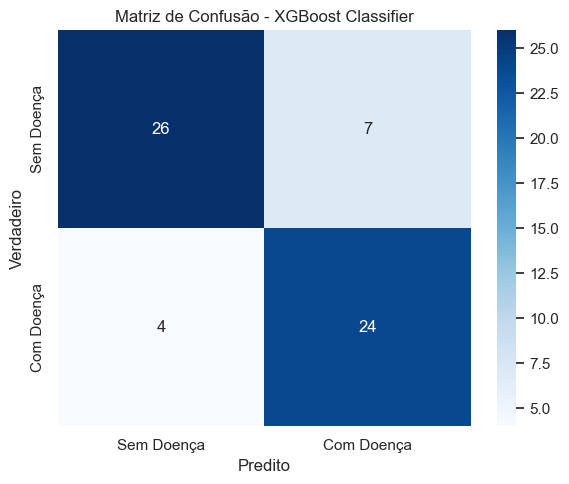

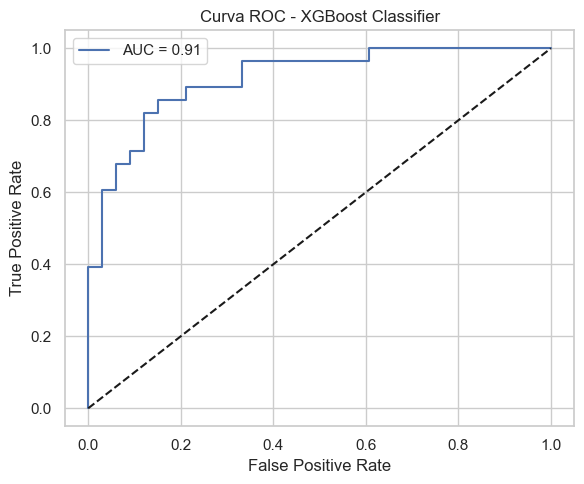

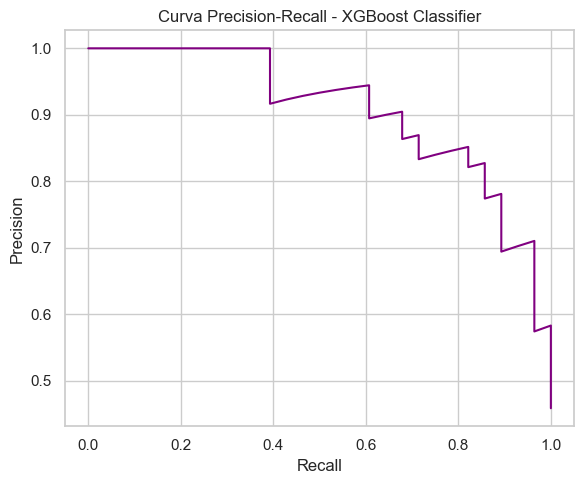

KS: 0.71
GINI: 0.83


In [4]:
# Importando as bibliotecas necessárias
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, roc_auc_score, precision_recall_curve
)
from scipy.stats import ks_2samp
from xgboost import XGBClassifier

# 🔹 Função para carregar o dataset Heart Disease
def carregar_dataset():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    colunas = [
        'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
        'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
    ]
    df = pd.read_csv(url, names=colunas, na_values='?')

    print("📌 Informações ANTES do tratamento de valores nulos:")
    df.info()
    print("\n🔍 Quantidade de valores ausentes por coluna:")
    print(df.isnull().sum(), "\n")

    # Preenchendo valores nulos com a mediana de cada coluna
    df['ca'] = df['ca'].fillna(df['ca'].median())
    df['thal'] = df['thal'].fillna(df['thal'].median())

    print("📌 Informações DEPOIS do tratamento de valores nulos:")
    df.info()
    print("\n📌 Estatísticas descritivas do dataset:")
    print(df.describe(), "\n")

    print("📌 Primeiras 5 linhas do dataset Heart Disease:")
    print(df.head(), "\n")
    print(f"📌 Quantidade final de registros: {len(df)}\n")

    X = df.drop(columns=['target'])
    y = df['target'].apply(lambda x: 1 if x > 0 else 0)
    return X, y

# 🔹 Avaliação do modelo com várias métricas e gráficos
def avaliar_modelo(modelo, X_train, y_train, X_test, y_test):
    y_pred_train = modelo.predict(X_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred)
    cv_score = cross_val_score(
        modelo, X_train, y_train, cv=5, scoring='accuracy'
    ).mean()

    print(f"✅ Acurácia no Treino: {acc_train:.2f}")
    print(f"✅ Acurácia no Teste: {acc_test:.2f}")
    print(f"📉 Validação Cruzada (Treino): {cv_score:.2f}")

    if acc_train - acc_test > 0.10:
        print("⚠️ Possível Overfitting detectado!\n")

    print("\n📊 Relatório de Classificação:")
    print(classification_report(
        y_test, y_pred,
        target_names=['Sem Doença', 'Com Doença'],
        zero_division=0
    ))

    # 🔵 Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=['Sem Doença', 'Com Doença'],
                yticklabels=['Sem Doença', 'Com Doença'])
    plt.xlabel("Predito")
    plt.ylabel("Verdadeiro")
    plt.title("Matriz de Confusão - XGBoost Classifier")
    plt.tight_layout()
    plt.show()

    # 🟠 Curva ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Curva ROC - XGBoost Classifier")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 🟣 Precision-Recall
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, color='purple')
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Curva Precision-Recall - XGBoost Classifier")
    plt.tight_layout()
    plt.show()

    # 📉 KS e GINI
    ks = ks_2samp(y_prob[y_test == 1], y_prob[y_test == 0]).statistic
    gini = 2 * auc_score - 1
    print(f"KS: {ks:.2f}")
    print(f"GINI: {gini:.2f}")

# 🚀 Execução principal
X, y = carregar_dataset()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📚 Registros no Treino: {len(X_train)}")
print(f"🧪 Registros no Teste: {len(X_test)}")

# 🔍 Hiperparâmetros com regularização para evitar overfitting
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.6, 0.8, 1.0]
}

# 🤖 Alteração principal: GradientBoostingClassifier → XGBClassifier
grid = GridSearchCV(
    XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=42,
        n_jobs=1
    ),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)
melhor_modelo = grid.best_estimator_

print(f"\n🏆 Melhor combinação de parâmetros: {grid.best_params_}")
avaliar_modelo(melhor_modelo, X_train, y_train, X_test, y_test)
